In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tfswin import SwinTransformerTiny224
import matplotlib.pyplot as plt

In [2]:
(train_x, train_y), (test_x, test_y) = tf.keras.datasets.cifar100.load_data()

In [3]:
num_classes = 100

inputs = layers.Input(shape=(32, 32, 3), dtype='uint8')

x = layers.Resizing(
    224,
    224,
    interpolation='bicubic'
)(inputs)

x = SwinTransformerTiny224(
    include_top=False
)(x)

x = layers.GlobalAveragePooling2D()(x)

outputs = layers.Dense(
    num_classes,
    activation='softmax'
)(x)

swin = models.Model(
    inputs=inputs,
    outputs=outputs
)

In [4]:
optimizer = tf.keras.optimizers.Adam()

swin.compile(
    optimizer = optimizer,
    loss = 'sparse_categorical_crossentropy',
    metrics = [tf.keras.metrics.SparseTopKCategoricalAccuracy(1, name = 'accuracy'),
               tf.keras.metrics.SparseTopKCategoricalAccuracy(5, name = 'top-5-accuracy')]
)

In [5]:
history = swin.fit(x = train_x,
                   y = train_y,
                   batch_size = 128,
                   epochs = 10,
                   validation_split = 0.2)

Epoch 1/10

313/313 [==============================] - 3402s 11s/step - loss: 4.6498 - accuracy: 0.0098 - top-5-accuracy: 0.0503 - val_loss: 4.6265 - val_accuracy: 0.0091 - val_top-5-accuracy: 0.0476
Epoch 2/10
313/313 [==============================] - 3499s 11s/step - loss: 4.6321 - accuracy: 0.0099 - top-5-accuracy: 0.0483 - val_loss: 4.6227 - val_accuracy: 0.0106 - val_top-5-accuracy: 0.0475
Epoch 3/10
108/313 [=========>....................] - ETA: 41:47 - loss: 4.6273 - accuracy: 0.0099 - top-5-accuracy: 0.0474

KeyboardInterrupt: 

NameError: name 'history' is not defined

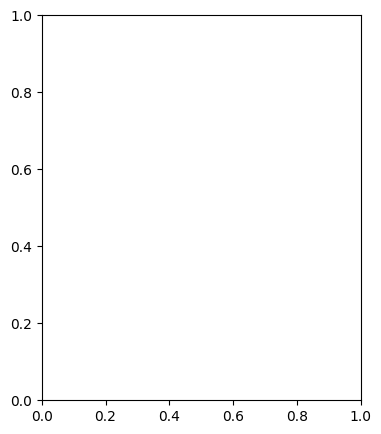

In [6]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(history.history['top-5-accuracy'], label='Training Top-5 Accuracy')
plt.plot(history.history['val_top-5-accuracy'], label='Validation Top-5 Accuracy')
plt.title('Training and Validation Top-5 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Top-5 Accuracy')
plt.ylim(0, 1)
plt.legend()
plt.show()

In [7]:
swin.evaluate(test_x, test_y)

  6/313 [..............................] - ETA: 13:25 - loss: 4.6021 - accuracy: 0.0000e+00 - top-5-accuracy: 0.0573

KeyboardInterrupt: 